# U.S. Retail Sales Forecast

**Question:** how well can a classic time series model forecast a full year of U.S. monthly retail sales, including the unusual period after COVID-19?

**Data:** U.S. monthly retail sales in millions of dollars, January 1992 to June 2021 (354 months).

**Approach:** reshape the data into a monthly time series, train a Holt-Winters exponential smoothing model (additive trend and 12-month seasonality) on everything before July 2020, forecast July 2020 to June 2021, and compare the forecast with the actual sales and with a naive baseline.

**Key results:**
- The forecast's RMSE is 45,157 million dollars (MAPE 6.5%), about 8.8% of average monthly sales in the test year.
- That is only 7.8% better than a naive forecast that repeats the last known month (RMSE 48,985, MAPE 7.1%).
- The model under-forecast every month. Misses were 1.2% to 3.5% through December 2020 but grew to 11.7% to 14.4% from March to June 2021, when sales rose well above their historical trend.

**Tools:** Python (pandas, statsmodels, scikit-learn, matplotlib)

**Context:** master's coursework (DSC630, Week 8), cleaned up for this portfolio.

## 1. Load and reshape the data

In [1]:
# import required libraries
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing   # Holt-Winters exponential smoothing
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

warnings.filterwarnings('ignore', category=FutureWarning)

In [2]:
# U.S. monthly retail sales (millions of dollars): one row per year, one column per month
df = pd.read_csv('us_retail_sales.csv')
print(df.shape)
df.head()

(30, 13)


,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC
0,1992,146925,147223,146805,148032,149010,149800,150761.0,151067.0,152588.0,153521.0,153583.0,155614.0
1,1993,157555,156266,154752,158979,160605,160127,162816.0,162506.0,163258.0,164685.0,166594.0,168161.0
2,1994,167518,169649,172766,173106,172329,174241,174781.0,177295.0,178787.0,180561.0,180703.0,181524.0
3,1995,182413,179488,181013,181686,183536,186081,185431.0,186806.0,187366.0,186565.0,189055.0,190774.0
4,1996,189135,192266,194029,194744,196205,196136,196187.0,196218.0,198859.0,200509.0,200174.0,201284.0


In [3]:
# the last year only has January to June, so July to December are blank
df.isna().sum()

YEAR    0
JAN     0
FEB     0
MAR     0
APR     0
MAY     0
JUN     0
JUL     1
AUG     1
SEP     1
OCT     1
NOV     1
DEC     1
dtype: int64

In [4]:
# reshape to one row per month and build a DATE column, so the data can be treated as a time series
df_melted = df.melt(id_vars=['YEAR'], var_name='MONTH', value_name='SALES')
df_melted['DATE'] = pd.to_datetime(df_melted['YEAR'].astype(str) + '-' + df_melted['MONTH'], format='%Y-%b')
df_melted = df_melted.dropna(subset=['SALES']).sort_values('DATE').set_index('DATE')
print(f"{len(df_melted)} months, {df_melted.index.min():%B %Y} to {df_melted.index.max():%B %Y}")

354 months, January 1992 to June 2021


## 2. Look at the trend

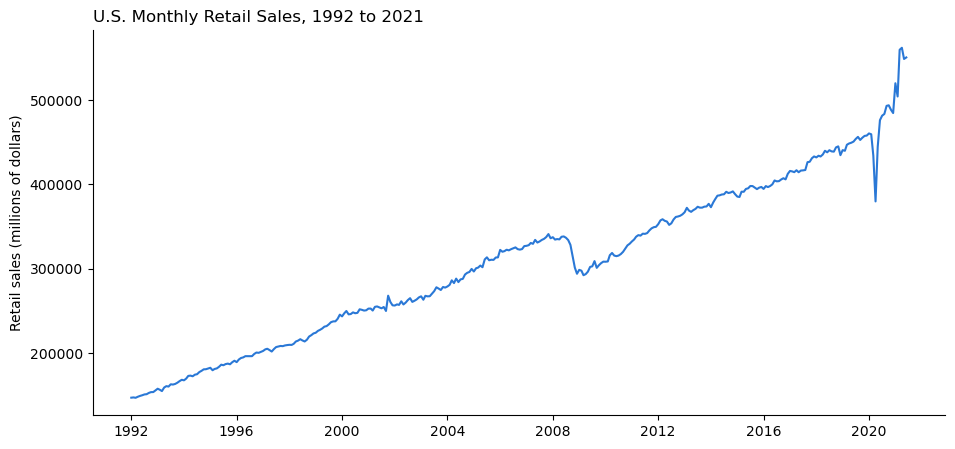

Years when annual sales fell:
YEAR
2008   -1.7
2009   -8.0

2008 peak (Jun 2008) to 2009 low (Mar 2009): -13.6%
Feb 2020 to Apr 2020: -17.3%
2020 full year vs. 2019: 3.1%


In [5]:
plt.figure(figsize=(11, 5))
plt.plot(df_melted.index, df_melted['SALES'], color='#2a78d6', lw=1.5)
plt.ylabel('Retail sales (millions of dollars)')
plt.title('U.S. Monthly Retail Sales, 1992 to 2021', loc='left')
plt.gca().spines[['top', 'right']].set_visible(False)
plt.show()

# year-over-year change in annual sales (full years only), to check the dips seen in the chart
annual = df_melted[df_melted['YEAR'] < 2021].groupby('YEAR')['SALES'].sum()
yoy = annual.pct_change() * 100
print('Years when annual sales fell:')
print(yoy[yoy < 0].round(1).to_string())

# the two sharpest month-level drops
s = df_melted['SALES']
print(f"\n2008 peak ({s['2008'].idxmax():%b %Y}) to 2009 low ({s['2009'].idxmin():%b %Y}): {s['2009'].min() / s['2008'].max() - 1:.1%}")
print(f"Feb 2020 to Apr 2020: {s['2020-04-01'] / s['2020-02-01'] - 1:.1%}")
print(f"2020 full year vs. 2019: {annual[2020] / annual[2019] - 1:.1%}")

**Observations:**
- Sales rise steadily over almost 30 years.
- The two sharpest drops line up with the 2008 financial crisis (down 13.6% from June 2008 to March 2009; annual sales fell in both 2008 and 2009) and the start of COVID-19 (down 17.3% from February to April 2020).
- The 2020 drop was short: sales recovered by June, and 2020 as a whole finished 3.1% above 2019.
- Smaller ups and downs within each year are seasonal.

## 3. Split into training and test sets
The test set is the last full year of data, July 2020 to June 2021. Everything before July 2020 is used for training.

In [6]:
train = df_melted.loc[:'2020-06-01', ['SALES']].asfreq('MS')
test = df_melted.loc['2020-07-01':'2021-06-01', ['SALES']]
print(f'Training months: {len(train)}   Test months: {len(test)}')

Training months: 342   Test months: 12


## 4. Build the forecasting model
Holt-Winters exponential smoothing with an additive trend and a 12-month additive seasonal pattern. (A SARIMA model was tried first but would not fit.)

In [7]:
model = ExponentialSmoothing(train['SALES'], trend='add', seasonal='add', seasonal_periods=12)
with warnings.catch_warnings(record=True) as caught:   # capture warnings so they print as a short note
    warnings.simplefilter('always')
    fitted_model = model.fit()
for w in caught:
    print(f'Note from statsmodels: {w.category.__name__}: {w.message}')
test_predictions = fitted_model.forecast(len(test))

Note from statsmodels: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.


## 5. Evaluate the forecast
RMSE (root mean squared error) is the typical size of a monthly miss, in millions of dollars. To judge whether it is good, it is compared with a naive baseline that simply repeats the last training month (June 2020) for every month of the test year.

In [8]:
naive_predictions = pd.Series(train['SALES'].iloc[-1], index=test.index)

def scores(pred):
    return {'RMSE (millions $)': np.sqrt(mean_squared_error(test['SALES'], pred)),
            'MAPE (%)': mean_absolute_percentage_error(test['SALES'], pred) * 100}

results = pd.DataFrame([scores(test_predictions), scores(naive_predictions)],
                       index=['Holt-Winters', 'Naive (repeat June 2020)']).round(1)
print(f"Average monthly sales in the test year: {test['SALES'].mean():,.0f} million")
results

Average monthly sales in the test year: 514,385 million


,RMSE (millions $),MAPE (%)
Holt-Winters,45157.0,6.5
Naive (repeat June 2020),48984.7,7.1


In [9]:
comparison = pd.DataFrame({'actual': test['SALES'], 'holt_winters': test_predictions.round(0)})
comparison['miss_pct'] = ((comparison['holt_winters'] - comparison['actual']) / comparison['actual'] * 100).round(1)
comparison

,actual,holt_winters,miss_pct
2020-07-01,481627.0,474568.0,-1.5
2020-08-01,483716.0,475414.0,-1.7
2020-09-01,493327.0,476023.0,-3.5
2020-10-01,493991.0,477203.0,-3.4
2020-11-01,488652.0,478050.0,-2.2
2020-12-01,484782.0,479028.0,-1.2
2021-01-01,520162.0,479927.0,-7.7
2021-02-01,504458.0,480303.0,-4.8
2021-03-01,559871.0,480722.0,-14.1
2021-04-01,562269.0,481052.0,-14.4


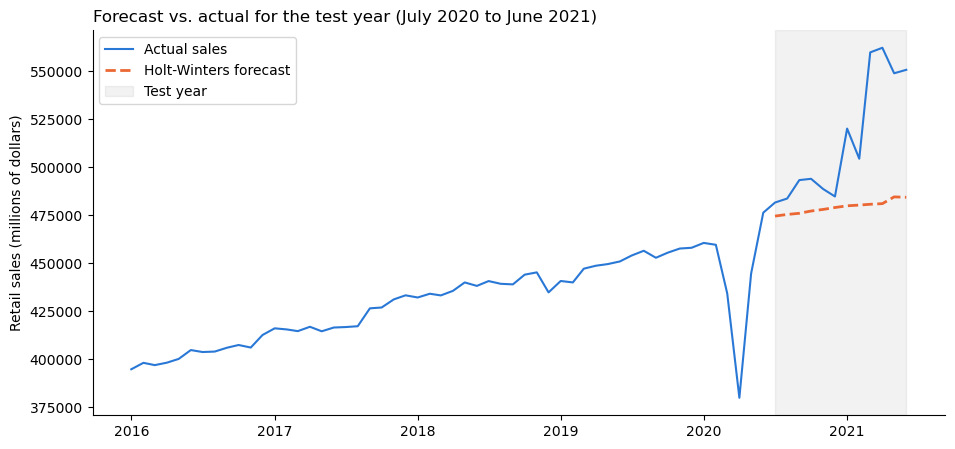

In [10]:
plt.figure(figsize=(11, 5))
recent = df_melted.loc['2016-01-01':]
plt.plot(recent.index, recent['SALES'], color='#2a78d6', lw=1.5, label='Actual sales')
plt.plot(test.index, test_predictions, color='#eb6834', lw=2, linestyle='--', label='Holt-Winters forecast')
plt.axvspan(test.index.min(), test.index.max(), color='grey', alpha=0.1, label='Test year')
plt.ylabel('Retail sales (millions of dollars)')
plt.title('Forecast vs. actual for the test year (July 2020 to June 2021)', loc='left')
plt.legend(loc='upper left')
plt.gca().spines[['top', 'right']].set_visible(False)
plt.show()

## Findings
- **The forecast is reasonable but only slightly better than a naive guess.** Holt-Winters has an RMSE of 45,157 million dollars (MAPE 6.5%) on the test year, compared with 48,985 (MAPE 7.1%) for simply repeating June 2020's sales every month.
- **It under-forecast every month.** The misses were 1.2% to 3.5% from July to December 2020, then 7.7% in January 2021, 4.8% in February, and 11.7% to 14.4% from March to June 2021, when actual sales jumped from about 505,000 million in February to about 560,000 million in March and stayed near that level.
- **Why:** the model projects the pre-2020 trend and seasonal pattern forward. It has no way to anticipate a sudden shift in spending, so a structural break like 2020-2021 is exactly where this kind of model struggles.
- **Limitations and next steps:** the model also reported that its optimizer did not fully converge. Next steps would be a model that can include outside factors (for example SARIMAX with economic indicators), a rolling forecast that refits each month, and comparing a multiplicative seasonal pattern.